# 03 — Líneas base

**Objetivo.** Fijar las cuatro referencias contra las que se medirá el modelo del TFM y
comprobar, con datos, que el error de regresión y la utilidad clínica no son la misma cosa.

**Entradas.** `experiments/results/<exp_id>/metrics.json`, producidos por
`python -m tfm.training.run --config experiments/configs/<exp_id>.yaml`.

**Salidas.** Tabla de líneas base a 30 y 60 min, test de Wilcoxon pareado por paciente, y las
figuras `03_baselines_rmse_vs_recall`, `03_recall_ic` y `03_recall_por_paciente`.

**Protocolo de evaluación** (ver `tfm.eval.protocol`): tolerancia de detección de 15 min,
inicios de evento anclados a la CGM oficial y **61 eventos puntuables**, los mismos en ambos
horizontes.

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt

from tfm.eval.compare import comparison_table, paired_wilcoxon, load_result
from tfm.eval.protocol import EVENT_TOLERANCE_MIN
from tfm.viz import CATEGORICAL, FIG_WIDTH_FULL, ROLE
from tfm.viz.plots import set_style, save_figure, plot_recall_with_ci

set_style()
pd.set_option("display.width", 140)

EXPERIMENTS = [
    "20260915-baseline-persistencia",
    "20260916-baseline-ridge",
    "20260916-baseline-lstm-paciente",
    "20260916-baseline-lstm-global",
]
NOMBRES = {
    "20260915-baseline-persistencia": "0 · persistencia",
    "20260916-baseline-ridge": "1 · ridge por paciente",
    "20260916-baseline-lstm-paciente": "2 · LSTM por paciente",
    "20260916-baseline-lstm-global": "3 · LSTM global",
}
HORIZONTES = (30, 60)
print(f"Tolerancia de detección: {EVENT_TOLERANCE_MIN} min")

Tolerancia de detección: 15 min


## 1. Las cuatro líneas base

Cada fila lleva error de regresión **y** métrica clínica, como exige el protocolo del TFM.
`recall` es el recall agregado por eventos sobre los 12 pacientes, con su intervalo bootstrap;
`n_events` es el denominador absoluto.

In [2]:
tablas = {}
for h in HORIZONTES:
    t = comparison_table(EXPERIMENTS, h)
    t["exp_id"] = t["exp_id"].map(NOMBRES)
    tablas[h] = t
    print(f"\n===== Horizonte de predicción: {h} min =====")
    print(t[["exp_id", "rmse", "rmse_sd_seeds", "recall", "recall_ci_lo", "recall_ci_hi",
             "n_events", "false_alarms_per_day", "parkes_AB", "parkes_DE"]]
          .to_string(index=False, float_format=lambda x: f"{x:7.3f}"))


===== Horizonte de predicción: 30 min =====
                exp_id    rmse  rmse_sd_seeds  recall  recall_ci_lo  recall_ci_hi  n_events  false_alarms_per_day  parkes_AB  parkes_DE
      0 · persistencia  23.498          0.000   0.098         0.033         0.180        61                 0.209     99.650      0.000
1 · ridge por paciente  19.412          0.000   0.279         0.164         0.393        61                 0.426     99.773      0.003
 2 · LSTM por paciente  21.880          0.363   0.077         0.033         0.180        61                 0.000     99.610      0.000
       3 · LSTM global  19.024          0.071   0.038         0.000         0.115        61                 0.104     99.733      0.000

===== Horizonte de predicción: 60 min =====
                exp_id    rmse  rmse_sd_seeds  recall  recall_ci_lo  recall_ci_hi  n_events  false_alarms_per_day  parkes_AB  parkes_DE
      0 · persistencia  38.550          0.000   0.066         0.016         0.131        61   

[PosixPath('memoria/figuras/03_baselines_rmse_vs_recall.pdf'),
 PosixPath('memoria/figuras/03_baselines_rmse_vs_recall.png')]

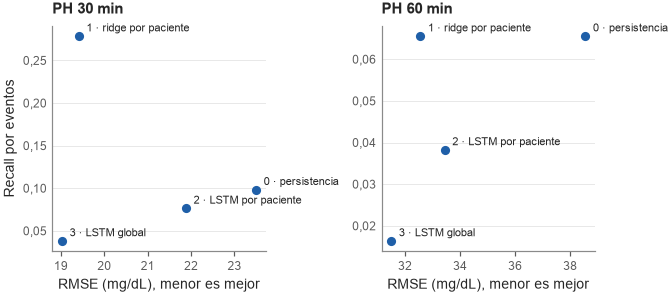

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH_FULL, 2.9))
for ax, h in zip(axes, HORIZONTES):
    t = tablas[h]
    ax.scatter(t["rmse"], t["recall"], s=36, color=ROLE["modelo"], zorder=3)
    for _, r in t.iterrows():
        ax.annotate(r["exp_id"], (r["rmse"], r["recall"]), textcoords="offset points",
                    xytext=(5, 3), fontsize=7)
    ax.set_xlabel("RMSE (mg/dL), menor es mejor")
    ax.set_title(f"PH {h} min")
axes[0].set_ylabel("Recall por eventos")
fig.tight_layout()
save_figure(fig, "03_baselines_rmse_vs_recall")

Si las dos métricas midieran lo mismo, los puntos caerían en una diagonal
descendente. A 30 minutos ocurre lo contrario: los dos modelos con mejor RMSE están abajo del
todo en recall. A 60 minutos todos los recalls se hunden por debajo de 0,07 y la distinción
deja de ser informativa: **ningún baseline sirve para avisar con una hora de antelación**.

[PosixPath('memoria/figuras/03_recall_ic.pdf'),
 PosixPath('memoria/figuras/03_recall_ic.png')]

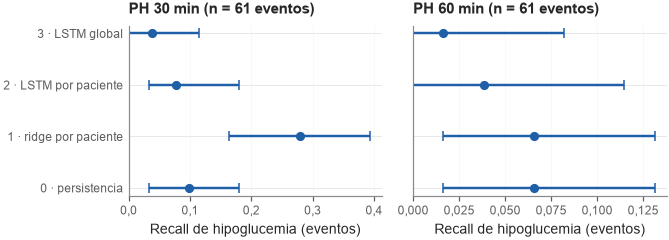

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH_FULL, 2.4), sharey=True)
for ax, h in zip(axes, HORIZONTES):
    plot_recall_with_ci(ax, tablas[h])
    ax.set_title(f"PH {h} min (n = {int(tablas[h]['n_events'].iloc[0])} eventos)")
fig.tight_layout()
save_figure(fig, "03_recall_ic")

Los intervalos son anchos y se solapan casi todos: con 61 eventos, una
diferencia de cinco puntos de recall no es un resultado. La única separación que sobrevive al
intervalo a 30 minutos es la del ridge frente al resto. Por eso la comparación formal se hace
**pareada por paciente**, que es más potente que comparar dos agregados.

## 2. Significación: Wilcoxon pareado por paciente

Con N=12 no se asume normalidad. Se comparan las métricas paciente a paciente, que es la
comparación que la memoria debe presentar.

In [5]:
pares = [
    ("20260916-baseline-ridge", "20260915-baseline-persistencia"),
    ("20260916-baseline-lstm-paciente", "20260915-baseline-persistencia"),
    ("20260916-baseline-lstm-global", "20260915-baseline-persistencia"),
    ("20260916-baseline-lstm-global", "20260916-baseline-ridge"),
    ("20260916-baseline-lstm-global", "20260916-baseline-lstm-paciente"),
]
filas = []
for h in HORIZONTES:
    for a, b in pares:
        for metrica in ("rmse", "recall"):
            r = paired_wilcoxon(a, b, h, metrica)
            filas.append({"PH": h, "comparación": f"{NOMBRES[a]} vs {NOMBRES[b]}",
                          "métrica": metrica, "dif. mediana": r["median_diff"],
                          "p": r["p_value"]})
wilcoxon = pd.DataFrame(filas)
wilcoxon["signif."] = wilcoxon["p"].apply(lambda p: "*" if p == p and p < 0.05 else "")
print(wilcoxon.to_string(index=False, float_format=lambda x: f"{x:8.4f}"))

 PH                                comparación métrica  dif. mediana        p signif.
 30 1 · ridge por paciente vs 0 · persistencia    rmse       -3.9797   0.0005       *
 30 1 · ridge por paciente vs 0 · persistencia  recall        0.0455   0.0312       *
 30  2 · LSTM por paciente vs 0 · persistencia    rmse       -1.7552   0.0210       *
 30  2 · LSTM por paciente vs 0 · persistencia  recall        0.0000   0.5625        
 30        3 · LSTM global vs 0 · persistencia    rmse       -4.3035   0.0005       *
 30        3 · LSTM global vs 0 · persistencia  recall        0.0000   0.1250        
 30  3 · LSTM global vs 1 · ridge por paciente    rmse       -0.3505   0.3013        
 30  3 · LSTM global vs 1 · ridge por paciente  recall       -0.2338   0.0156       *
 30   3 · LSTM global vs 2 · LSTM por paciente    rmse       -2.2751   0.0005       *
 30   3 · LSTM global vs 2 · LSTM por paciente  recall        0.0000   0.3750        
 60 1 · ridge por paciente vs 0 · persistencia    rmse

Las tres líneas base aprendidas baten a la persistencia en RMSE con
p=0,0005–0,02. Pero la comparación decisiva es **LSTM global frente a ridge a 30 minutos**:
la diferencia de RMSE **no es significativa** (p=0,30) mientras que la de recall **sí lo es**
y a favor del ridge (p=0,016, diferencia mediana de 0,234).

## 3. Por qué el global falla en la cola

Los modelos entrenados con MSE se encogen hacia la media. Contamos con qué frecuencia cada
línea base se atreve a predecir por debajo de 70 mg/dL, frente a la prevalencia real.

In [6]:
from tfm.paths import RESULTS_DIR

filas = []
for exp in EXPERIMENTS:
    df = pd.read_parquet(RESULTS_DIR / exp / "predictions.parquet")
    if "seed" in df.columns:
        df = df[df["seed"] == df["seed"].min()]
    d = df[df["horizon_min"] == 30]
    filas.append({
        "línea base": NOMBRES[exp],
        "predicciones < 70 (%)": 100 * (d["y_pred"] < 70).mean(),
        "reales < 70 (%)": 100 * (d["y_true"] < 70).mean(),
        "mínimo predicho (mg/dL)": d["y_pred"].min(),
        "desv. típica predicha": d["y_pred"].std(),
        "desv. típica real": d["y_true"].std(),
    })
cola = pd.DataFrame(filas)
print(cola.to_string(index=False, float_format=lambda x: f"{x:9.2f}"))

            línea base  predicciones < 70 (%)  reales < 70 (%)  mínimo predicho (mg/dL)  desv. típica predicha  desv. típica real
      0 · persistencia                   2.73             2.77                    40.00                  60.02              60.21
1 · ridge por paciente                   2.06             2.77                   -37.19                  56.67              60.21
 2 · LSTM por paciente                   1.03             2.77                    49.90                  56.11              60.21
       3 · LSTM global                   1.13             2.77                    45.92                  56.79              60.21


La prevalencia real de ventanas hipoglucémicas es del 2,77 %. Los dos LSTM
solo predicen por debajo de 70 en el 1,0–1,1 % de los casos: **se encogen hacia la media y
renuncian a la cola**, que es exactamente donde está el evento clínico.

El ridge llega al 2,06 % porque extrapola, y de ahí su recall. Pero el precio aparece en la
misma tabla: su predicción mínima es **negativa** (−37 mg/dL), un valor fisiológicamente
imposible. Un despliegue real tendría que recortar la salida a un rango válido, y eso
recortaría también parte de su ventaja en recall. No es una línea base gratis.

**Esto motiva directamente la contribución del TFM:** si el problema es que un modelo entrenado
con MSE no se compromete en la cola, la respuesta no es un umbral sobre la media, sino emitir
(μ, log σ²) y alarmar con **P(y < 70) > α**, con α ajustable clínicamente.

## 4. Por paciente

Con N=12 la media esconde el resultado. Seis pacientes tienen menos de cinco eventos en su
test, así que **el recall individual no se interpreta**: la columna `n_events` está aquí para
recordarlo.

In [7]:
from tfm.eval.compare import _horizon_block

por_paciente = {}
for exp in EXPERIMENTS:
    _, t = _horizon_block(load_result(exp), 30)
    por_paciente[NOMBRES[exp]] = t.set_index("patient")["recall"]
eventos = t.set_index("patient")["n_events"]

comp = pd.DataFrame(por_paciente)
comp.insert(0, "n_events", eventos)
print("Recall por paciente a 30 min (n_events = denominador real)")
print(comp.to_string(float_format=lambda x: f"{x:6.2f}"))

Recall por paciente a 30 min (n_events = denominador real)
         n_events  0 · persistencia  1 · ridge por paciente  2 · LSTM por paciente  3 · LSTM global
patient                                                                                            
540         11.00              0.00                    0.36                   0.00             0.00
544          2.00              0.50                    0.50                   0.00             0.00
552          7.00              0.14                    0.14                   0.05             0.14
559          3.00              0.00                    0.33                   0.00             0.00
563          2.00              0.00                    0.50                   0.00             0.00
567          5.00              0.20                    0.20                   0.40             0.20
570          2.00              0.00                    0.00                   0.00             0.00
575          8.00              0.12      

[PosixPath('memoria/figuras/03_recall_por_paciente.pdf'),
 PosixPath('memoria/figuras/03_recall_por_paciente.png')]

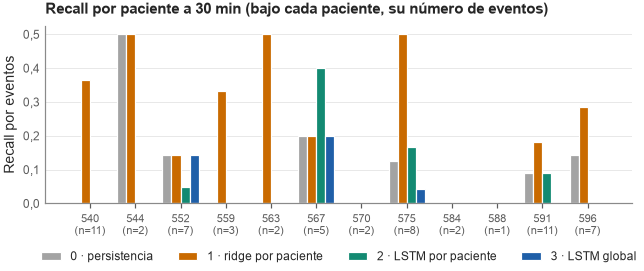

In [ ]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH_FULL, 2.8))
ancho = 0.2
x = range(len(comp))

colores = [ROLE["referencia"], CATEGORICAL[1], CATEGORICAL[2], CATEGORICAL[0]]
for i, col in enumerate(comp.columns[1:]):
    ax.bar([v + i * ancho for v in x], comp[col], ancho, label=col, color=colores[i],
           edgecolor="white", linewidth=0.8)
ax.set_xticks([v + 1.5 * ancho for v in x])
ax.set_xticklabels([f"{p}\n(n={int(n)})" for p, n in zip(comp.index, comp['n_events'])],
                   fontsize=7)
ax.set_ylabel("Recall por eventos")
ax.set_title("Recall por paciente a 30 min (bajo cada paciente, su número de eventos)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22))
fig.tight_layout()
save_figure(fig, "03_recall_por_paciente")

La dispersión entre pacientes es enorme y en varios casos el recall salta
entre 0 y 1 simplemente porque el denominador es 1 o 2 eventos. El paciente 588 tiene **un solo
evento** en todo su test: su columna es ruido, no señal.

Esto justifica dos decisiones del protocolo: reportar el **recall agregado por eventos** como
métrica principal, y hacer la comparación entre modelos con **Wilcoxon pareado por paciente**
en lugar de sobre una única cifra agregada.

## 5. Conclusiones

- Cuatro líneas base registradas y reproducibles, cada una con su `exp_id`, config YAML y
  `metrics.json`. Nada de este notebook calcula métricas: solo las carga.
- **Suelo a batir (test oficial, PH 30 / 60 min):**

  | Línea base | RMSE | Recall eventos |
  |---|---|---|
  | 0 · persistencia | 23,50 / 38,55 | 0,098 / 0,066 |
  | 1 · ridge por paciente | 19,41 / 32,56 | **0,279** / 0,066 |
  | 2 · LSTM por paciente | 21,88 / 33,44 | 0,077 / 0,038 |
  | 3 · LSTM global | **19,02** / **31,50** | 0,038 / 0,016 |


- **El mejor RMSE es el peor detector.** A 30 min la diferencia de RMSE entre global y ridge no
  es significativa (p=0,30) pero la de recall sí (p=0,016), a favor del ridge.
- **Entrenar un LSTM por paciente es peor que un ridge lineal.** Con ~8.000 ventanas por
  paciente el modelo sobreajusta; el barrido sobre validación apenas movió la pérdida, así que
  es un límite de tamaño de muestra, no de ajuste. Justifica el enfoque global + personalización.